# Giorgos Moirotsos - University of Thessaly
# ECE352 Image Processing 
# Assignment 2


- **απαραίτητες βιβλιοθήκες**

In [1]:
import imageio.v2 as imageio
import numpy as np
import matplotlib.pyplot as plt
import cv2


# Άσκηση 1

(512, 512)


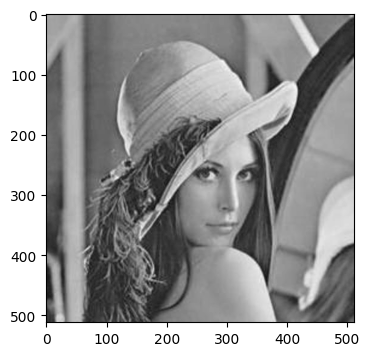

In [2]:
lena512 = imageio.imread('Lena512.jpg')
print(lena512.shape)

plt.figure(figsize=(8,4))
plt.imshow(lena512, cmap='gray')

# Βήματα
1. **Διαβάζουμε την εικόνα Lena512.jpg**
2. **Την μετατρέπουμε σε float64**
3. **Παιρνάω από το πεδίο του χώρου στο πεδίο της συχνότητας κάνοντας DFT (Discrete Fourier Transform). Συγκεκριμένα, η εικόνα μου μετατρέπεται σε ένα άθροισμα ημιτονοειδών σημάτων**
4. **Υπολογίζουμε το κεντραρισμένο DFT της εικόνας. Μετακινούμε το κέντρο του φάσματος από την πάνω αριστερή γωνία στο κέντρο της εικόνας.**
5. **Ελέγχουμε αν όντως η τιμή Η(0,0) στο DFT είναι ίση με την κεντραρισμένη τιμή στο DFT H(256,256) (επειδή το μέγεθος της εικόνας είναι (512,512))**

In [3]:
#convert into float
image_float = lena512.astype(np.float64)

#normalize
image_float = image_float / 255
print(image_float.dtype)
print(image_float.shape)

#compute dft
dft = np.fft.fft2(image_float)
dft_shifted = np.fft.fftshift(dft)
print(dft_shifted.shape)

# check the value in the center
print(dft[0][0])
print()
print(dft_shifted[256][256])



float64
(512, 512)
(512, 512)
(125987.50588235294+0j)

(125987.50588235294+0j)


# Άσκηση 1α

- **μέτρο και φάση του DFT της εικόνας, χρησιμοποιώντας abs και angle**

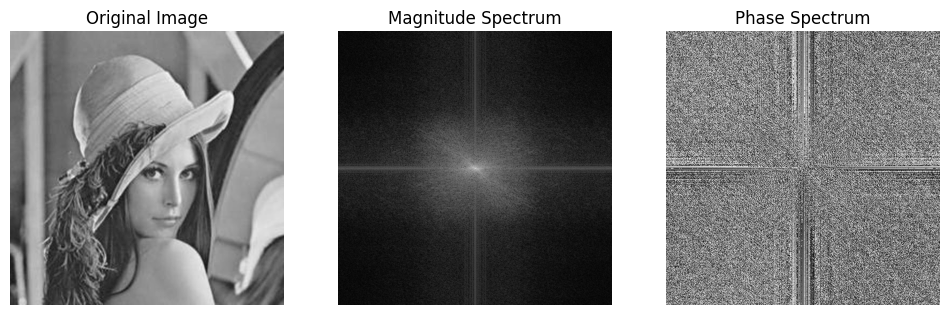

In [4]:
# Convert to complex array

# abs and phase
abs = np.abs(dft_shifted)
phase = np.angle(dft_shifted)

# Display
plt.figure(figsize=(12,10))

plt.subplot(131)
plt.imshow(lena512, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(132)
plt.imshow(np.log1p(abs), cmap='gray')
plt.title('Magnitude Spectrum')
plt.axis('off')

plt.subplot(133)
plt.imshow(phase, cmap='gray')
plt.title('Phase Spectrum')
plt.axis('off')

plt.show()

- **Το μέτρο αντιστοιχεί στην ένταση κάθε συχνότητας**
- **Η φάση καθορίζει τη θέση/ευθυγράμμιση των συχνοτήτων**

# Άσκηση 1β

- **Υπολογίστε τον αντίστροφο Μετασχηματισμό Fourier, διατηρώντας μόνο το πραγματικό μέρος**

# Βήματα
1. **Κάνω ξανά shift την τιμή του κέντρου, πάνω αριστερά (H(0,0))**
2. **Εφαρμόζω αντίστροφο Μετασχηματισμό Fourier (ifft2)**
3. **Παίρνω το μέτρο (magnitude) του αποτελέσματος, ώστε να διατηρήσω μόνο το πραγματικό μέρος**
4. **Εκτυπώνω το αποτέλεσμα. Παρατηρώ ότι η εικόνα είναι ίδια με την αρχική εικόνα**

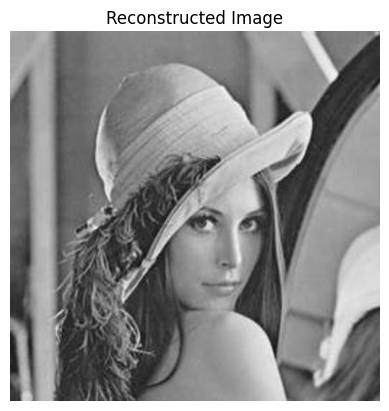

In [5]:
# 4. Shift back and apply inverse FFT
dft_unshifted = np.fft.ifftshift(dft_shifted)  # Shift zero freq back to top-left
reconstructed = np.fft.ifft2(dft_unshifted)    # Inverse DFT
result = np.abs(reconstructed)          # Take magnitude to get real image

# 5. Show result
plt.imshow(result, cmap='gray')
plt.title('Reconstructed Image')
plt.axis('off')
plt.show()

# Άσκηση 1γ

- **Υπολογίστε τον αντίστροφο Μετασχηματισμό Fourier, θέτοντας την φάση ίση με 0**

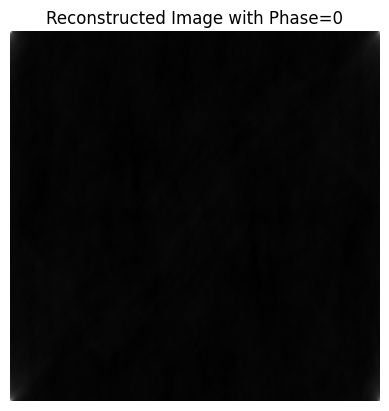

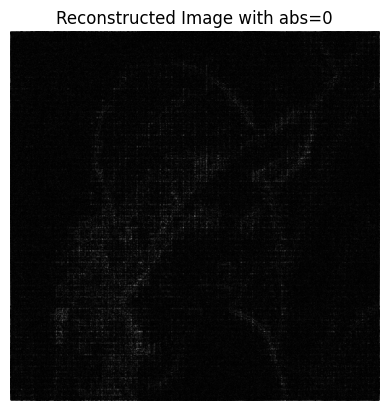

In [6]:
lena512 = imageio.imread('Lena512.jpg')
image_float = lena512.astype(np.float64)

dft = np.fft.fft2(image_float)
dft_shifted = np.fft.fftshift(dft)

#no phase
magnitude = np.abs(dft_shifted)
reconstructed_dft = magnitude * np.exp(1j * 0) 

# Shift back and apply inverse FFT
dft_unshifted = np.fft.ifftshift(reconstructed_dft)  # Shift zero freq back to top-left
reconstructed = np.fft.ifft2(dft_unshifted)    # Inverse DFT
result1 = np.abs(reconstructed)          # Take magnitude to get real image

# Show result
plt.imshow(result1, cmap='gray')
plt.title('Reconstructed Image with Phase=0')
plt.axis('off')
plt.show()

phase = np.angle(dft_shifted)
reconstructed_dft = np.exp(1j * phase)
# Shift back and apply inverse FFT
dft_unshifted = np.fft.ifftshift(reconstructed_dft)  # Shift zero freq back to top-left
reconstructed = np.fft.ifft2(dft_unshifted)    # Inverse DFT
result2 = np.abs(reconstructed) 

# Show result
plt.imshow(result2, cmap='gray')
plt.title('Reconstructed Image with abs=0')
plt.axis('off')
plt.show()

# Σχόλια:
1. **Φάση=0: σκοτεινό αποτέλεσμα, έχει χαθεί κάθε λεπτομέρεια της εικόνας. Αυτό συμβαίνει διότι η φάση δίνει την γεωμετρική λεπτομέρεια μιας εικόνας. Εάν η φάση είναι 0, δεν υπάρχει γεωμετρική λεπτομέρεια και τα κύματα δεν συνδυάζονται σωστά**
2. **Μέτρο=0: Η εικόνα έχει μηδενική πληροφορία, αφού |F(u,v)|=0 και F  (u,v) επίσης 0**
2. **Μέτρο=1: Στη δεύτερη εικόνα παρατηρείται (με δυσκολία) η γεωμετρία και η δομή της εικόνας, αφού διατηρούμε την φάση, αλλά δεν διατηρείται η φωτεινότητα της εικόνας. Αυτό συμβαίνει γιατί το μέτρο αντιστοιχεί στην ένταση κάθε συχνότητας και θέτοντας το μέτρο=1 (σταθερό), χάνουμε τις εντάσεις και την φωτεινότητα της εικόνας**

# Άσκηση 1δ

- **Χρησιμοποιήστε το μέτρο του DFT της εικόνας Lena512 και τη φάση του DFT της εικόνας Barbara512**

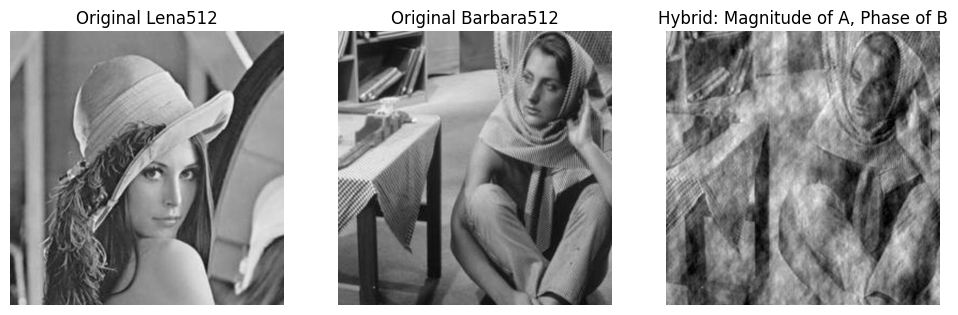

In [7]:
lena512 = imageio.imread('Lena512.jpg')
barbara512 = imageio.imread('Barbara512.jpg')

float_lena512 = lena512.astype(np.float64)
float_barbara = barbara512.astype(np.float64)

dft_lena512 = np.fft.fft2(float_lena512)
dft_shifted_lena512 = np.fft.fftshift(dft_lena512)

dft_barbara = np.fft.fft2(float_barbara)
dft_shifted_barbara = np.fft.fftshift(dft_barbara)

magnitude_lena512 = np.abs(dft_shifted_lena512)
phase_barbara = np.angle(dft_shifted_barbara)

hybrid_image = magnitude_lena512 * np.exp(1j * phase_barbara)

dft_unshifted = np.fft.ifftshift(hybrid_image)  # Shift zero freq back to top-left
result = np.fft.ifft2(dft_unshifted)
result = np.abs(result)

plt.figure(figsize=(12,12))

plt.subplot(131)
plt.imshow(lena512, cmap='gray')
plt.title('Original Lena512')
plt.axis('off')


plt.subplot(132)
plt.imshow(barbara512, cmap='gray')
plt.title('Original Barbara512')
plt.axis('off')


plt.subplot(133)
plt.imshow(result, cmap='gray')
plt.title('Hybrid: Magnitude of A, Phase of B')
plt.axis('off')
plt.show()


# Συμπέρασμα

- **Χρησιμοποιώντας το μέτρο της πρώτης εικόνας (Lena512) και την φάση της δεύτερης εικόνας (Barbara512), το αποτέλεσμα είναι πιο κοντά στην δεύτερη εικόνα**
- **Αυτό συμβαίνει γιατί η φάση είναι πιο σημαντική από το μέτρο, καθώς η φάση είναι αυτή που προσδιορίζει την δομή και την γεωμετρία μιας εικόνας**
- **Διαπιστώσαμε και στο προηγούμενο ερώτημα οτι η φάση είναι πιο σημαντική, αφού μηδενική φάση έδινε ένα μαύρο αποτέλεσμα**
- **Το μέτρο ,ωστόσο, καθορίζει την ένταση στη φωτεινότητα μιας εικόνας**
- **Συνεπώς, η τελική εικόνα διατηρεί την γεωμετρία της εικόνας Barbara512 λόγω της φάσης, αλλά διατηρεί την ένταση στη φωτεινότητα της εικόνας Lena512 λόγω του μέτρου**

# Άσκηση 2

- **διάβασε την εικόνα Lena.jpg, κάνε DFT και μετατόπισε το κέντρο**

In [8]:
#read the image
lena = imageio.imread('Lena.jpg')
print(lena.shape)

#float the image
lena = lena.astype(np.float64)
print(lena.shape)

#dft and shift [0,0] to the center
dft_lena = np.fft.fft2(lena)
dft_shifted_lena = np.fft.fftshift(dft_lena)
print(dft_shifted_lena.shape)


(256, 256)
(256, 256)
(256, 256)


# Άσκηση 2α

- **υλοποίηση συνάρτησης για ideal low pass filter**

In [9]:
def ideal_low_pass_filter(filter_size, shifted_image):
    
    height, width = shifted_image.shape
    D = np.zeros((height, width))
    H = np.zeros((height, width))
    u0 = height //2
    v0 = width//2
    D0 = filter_size

    for u in range(height):
        for v in range(width):
            D[u][v] = np.sqrt((u-u0)**2 +(v-v0)**2)
  
            if D[u][v] <= D0:
                H[u][v] = 1
            else:
                H[u][v] = 0
    

    return H
                


- **εφάρμοσε το κατωπερατό φίλτρο στην εικόνα**

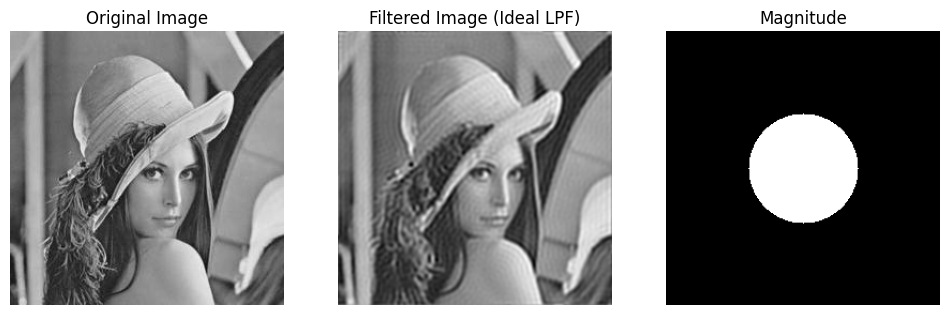

In [10]:
height, width = dft_shifted_lena.shape
H = np.zeros((height, width))

H = ideal_low_pass_filter(51, dft_shifted_lena)
#print(H)

filtered_lena = H * dft_shifted_lena
F_unshifted = np.fft.ifftshift(filtered_lena)
image_filtered= np.fft.ifft2(F_unshifted)
result = np.abs(image_filtered)

# compute magnitude of H
magnitude_H = np.abs(H)

#plot 
plt.figure(figsize=(12,10))

plt.subplot(131)
plt.imshow(lena, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(132)
plt.imshow(result, cmap='gray')
plt.title('Filtered Image (Ideal LPF)')
plt.axis('off')


plt.subplot(133)
plt.imshow(magnitude_H, cmap='gray')
plt.title('Magnitude')
plt.axis('off')
plt.show()


# Επεξήγηση
1. **Ένα ideal low pass filter διατηρεί τις χαμηλές συχνότητες και μηδενίζει τις υψηλές**
2. **Οι υψηλές συχνότητες περιλαμβάνουν την λεπτομέρεια (ακμές, γραμμές) μιας εικόνας. Γι' αυτό τον λόγο το αποτέλεσμα της δεύτερης εικόνας είναι πιο θολό και οι μικρές λεπτομέρειες (τρίχες, καπέλο, χαρακτηριστικά προσώπου) έχουν χαθεί, επειδή οι υψηλές συχνότητες έχουν μηδενιστεί**
3. **Το ideal low pass filter θολώνει την εικόνα και, συνεπώς, είναι σημαντικό για απομάκρυνση θορύβου**

# Άσκηση 2β

- **υλοποίηση συνάρτησης για ideal high pass filter**

In [11]:
def ideal_high_pass_filter(filter_size, shifted_image):
    
    height, width = shifted_image.shape
    D = np.zeros((height, width))
    H = np.zeros((height, width))
    u0 = height //2
    v0 = width//2
    D0 = filter_size

    for u in range(height):
        for v in range(width):
            D[u][v] = np.sqrt((u-u0)**2 +(v-v0)**2)
  
            if D[u][v] <= D0:
                H[u][v] = 0
            else:
                H[u][v] = 1
    

    return H
                


- **εφάρμοσε το υψιλοπερατό φίλτρο στην εικόνα**

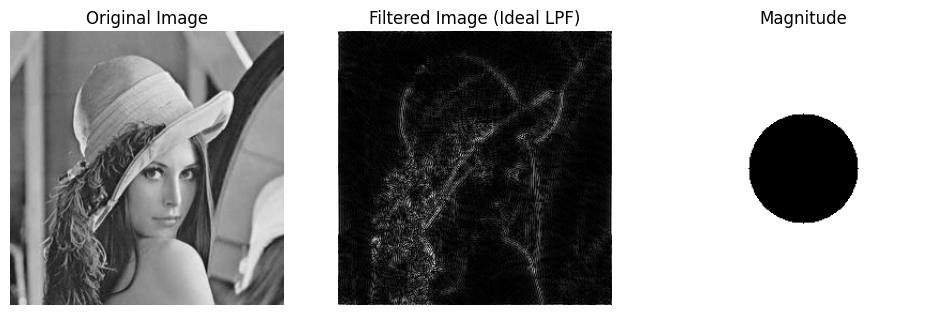

In [12]:
height, width = dft_shifted_lena.shape
H = np.zeros((height, width))

H = ideal_high_pass_filter(51, dft_shifted_lena)
#print(H)

filtered_lena = H * dft_shifted_lena
F_unshifted = np.fft.ifftshift(filtered_lena)
image_filtered= np.fft.ifft2(F_unshifted)
result = np.abs(image_filtered)

#compute magnitude
magnitude_H = np.abs(H)


#plot 
plt.figure(figsize=(12,10))

plt.subplot(131)
plt.imshow(lena, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(132)
plt.imshow(result, cmap='gray')
plt.title('Filtered Image (Ideal LPF)')
plt.axis('off')


plt.subplot(133)
plt.imshow(magnitude_H, cmap='gray')
plt.title('Magnitude')
plt.axis('off')
plt.show()



# Επεξήγηση
1. **Ένα ideal high pass filter διατηρεί τις υψηλές συχνότητες και μηδενίζει τις χαμηλές**
2. **Οι χαμηλές συχνότητες προσδιορίζουν την γενική φωτεινότητα της εικόνας, τις σκιές κτλ. Από τη στιγμή που μηδενίζουμε τις χαμηλές συχνότητες, η εικόνα μασ χάνει και τις αποχρώσεις/φωτεινότητά της**
3. **Το ideal high pass filter κρατάει μόνο ότι αλλάζει απότομα. Δηλαδή, τις λεπτομέρειες (ακμές, γραμμές, μεταβολή έντασης) της εικόνας**
4. **Ξεχωρίζουν οι λεπτομέρειες, σε αντίθεση με το προηγούμενο θολό απότελεσμα**
5. **Ιδανικό φίλτρο για ανίχνευση ακμών**

# Άσκηση 2γ

Magnitude of G:
[[7.51894207e-17 4.89416248e-17 6.07181018e-17 ... 1.32486277e-16
  2.37412716e-17 1.47033556e-17]
 [6.20378220e-17 2.16986115e-17 3.43659828e-17 ... 1.67224364e-16
  2.40811419e-17 2.16379481e-17]
 [2.68973597e-17 5.46685690e-17 4.22388934e-17 ... 2.35388594e-16
  1.07791450e-16 9.84484205e-17]
 ...
 [5.66160693e-17 1.03590812e-17 4.45612953e-17 ... 1.59588871e-16
  2.26635530e-17 4.28384301e-17]
 [7.23062321e-17 3.80032439e-17 6.34787526e-17 ... 1.61029639e-16
  2.84321563e-17 4.02323623e-17]
 [2.01163341e-17 5.27695118e-17 3.79432443e-17 ... 2.33138219e-16
  8.47059184e-17 1.01930493e-16]]

Magnitude of H:
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]

[[ 77 128]
 [ 78 118]
 [ 78 119]
 ...
 [178 137]
 [178 138]
 [179 128]]

Magnitude of H is 1 in [77][128]
Magnitude of G in this position is 0.9999999999999998

Magnitude of H is 1 in [78][118]
Magnitude of G i

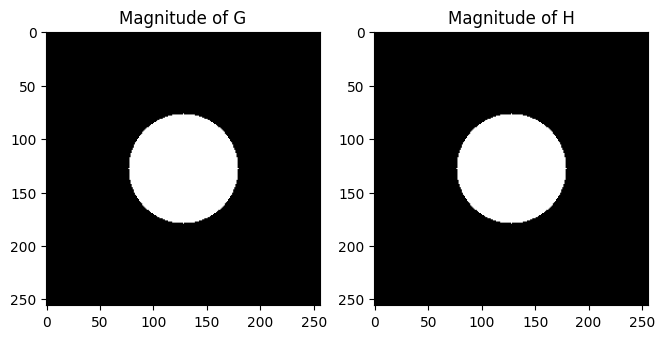

In [13]:
height, width = dft_shifted_lena.shape
H = np.zeros((height, width))

H = ideal_low_pass_filter(51, dft_shifted_lena)

# compute G 
G = np.fft.fft2(np.fft.ifft2(H))
magnitude_G = np.abs(G)
print("Magnitude of G:")
print(magnitude_G)
print()

# compute magnitude of H
magnitude_H = np.abs(H)
print("Magnitude of H:")
print(magnitude_H)
print()

#plot the magntitudes
plt.figure(figsize=(12,10))

plt.subplot(131)
plt.imshow(np.log1p(magnitude_G), cmap='gray')
plt.title('Magnitude of G')

plt.subplot(132)
plt.imshow(np.log1p(magnitude_H), cmap='gray')
plt.title('Magnitude of H')

# check if the value of H is 1, it is also 1 for G
print(np.argwhere(magnitude_H == 1))
print()

height, width = magnitude_H.shape
for i in range(height):
    for j in range(width):
        if magnitude_H[i][j] == 1:
            print(f"Magnitude of H is 1 in [{i}][{j}]")
            print(f"Magnitude of G in this position is {magnitude_G[i][j]}")
            print()
        else:
            continue


# Επεξήγηση
- **Στόχος είναι να συγκρίνουμε το μέτρο του H ιδανικού χαμηλοπερατού φίλτρου με το μέτρο του G, όπου G = DFT(( IDFT (H )))**
- **Το μέτρο του H αναμένεται να είναι 0 στα άκρα και 1 στο κέντρο**
- **Το G είναι ο μετασχηματισμός του αντίστροφου μετασχηματισμού του H, δηλαδή το ίδιο το H. Συνεπώς, αναμένεται το μέτρο του G να είναι επίσης 0 στα άκρα και 1 στο κέντρο**
- **Στις δύο εικόνες αποτύπωσεις του μέτρου των G και H, επιβεβαιώνεται το γεγονός ότι τα δύο μέτρα είναι ολόιδια**
- **Όταν εκτυπώνουμε τις τιμές των μέτρων, παρατηρούμε ότι οι τιμές του H στα άκρα είναι 0, ενώ οι τιμές του G στα άκρα είναι υπερβολικά μικρές της τάξης -17, δηλαδή σχεδόν μηδενικές. Αυτό συμβαίνει λόγω του υπολογιστικού σφάλματος του υπολογιστή. Γι' αυτό οι τιμές του G δεν είναι ακριβώς 0.**
- **Εκτυπώνουμε την θέση του H όπου έχει τιμή 1, καθώς και την τιμή του G στην ίδια θέση. Παρατηρούμε πως η τιμή του G είναι επίσης 1 ή εξαιρετικά κοντά στο 1. Αυτό συμβαίνει για τον ίδιο λόγο που περιγράψαμε προηγουμένως, το υπολογιστικό σφάλμα του υπολογιστή.**
- **Συνεπώς, το μέτρο του G είναι ίδιο με το μέτρο του H (βλέπε εικόνες), με εξαιρετικά μικρές διαφορές σε αριθμητικό επίπεδο, λόγω του υπολογιστικού σφάλματος**


# Άσκηση 2δ

In [25]:
def zero_padding(image, filter_size):

    m1 = image.shape[0]
    m2 = filter_size

    # zero padding for image
    P = m1+m2-1
    pad_image_total = P - m1
    pad_top = pad_image_total // 2
    pad_bottom = pad_image_total - pad_top

    pad_left = pad_image_total // 2
    pad_right = pad_image_total - pad_left

    padded_image = np.pad(image, ((pad_top, pad_bottom), (pad_left, pad_right)), mode='constant')

    return padded_image

In [103]:
def band_pass_filter(size, image):
    
        m1 = image.shape[0]
        m2 = size

        P = m1 + m2 - 1

        padded_filter = np.ones((P, P))

        for i in range(P):
            padded_filter[i][P//2] = 0

        #print(padded_filter)

        return padded_filter
        





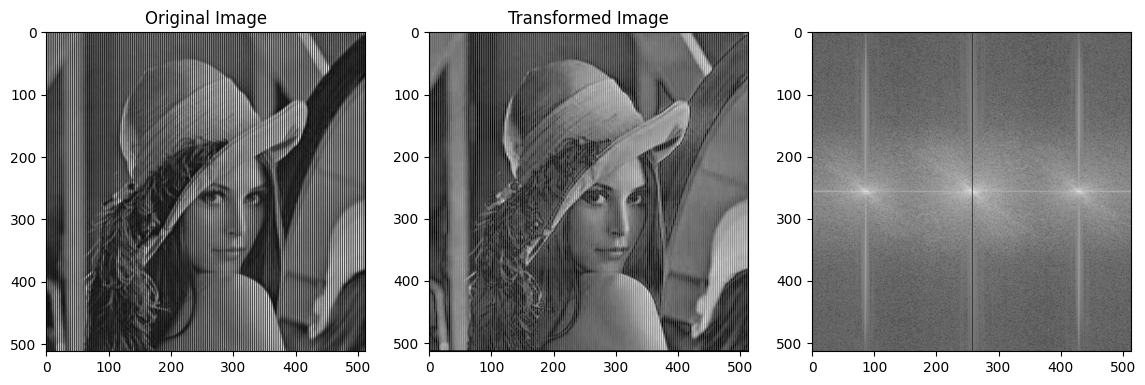

In [104]:
lena_barred = imageio.imread('LenaBarred1.jpg')
lena_barred = lena_barred.astype(np.float64)

filter_size = 3

lena_barred_padded = zero_padding(lena_barred, filter_size)

filter = band_pass_filter(filter_size, lena_barred)

lena_barred_dft = np.fft.fft2(lena_barred_padded)
lena_barred_dft_shifted = np.fft.fftshift(lena_barred_dft)
#wrapped = np.fft.ifftshift(filter)

G = lena_barred_dft_shifted * filter
magnitude_G = np.abs(G)
    
# Επαναφορά και ifft
F_unshifted = np.fft.ifftshift(G)
image_filtered = np.fft.ifft2(F_unshifted)
image_filtered = np.abs(image_filtered)

plt.figure(figsize=(14,14))

plt.subplot(131)
plt.imshow(lena_barred, cmap='gray')
plt.title('Original Image')

plt.subplot(132)
plt.imshow(image_filtered, cmap='gray')
plt.title('Transformed Image')


plt.subplot(133)
plt.imshow(np.log1p(magnitude_G), cmap='gray')

# Άσκηση 3α

(8030845+0j)

0j

0.0


Text(0.5, 1.0, 'Result after IFFT')

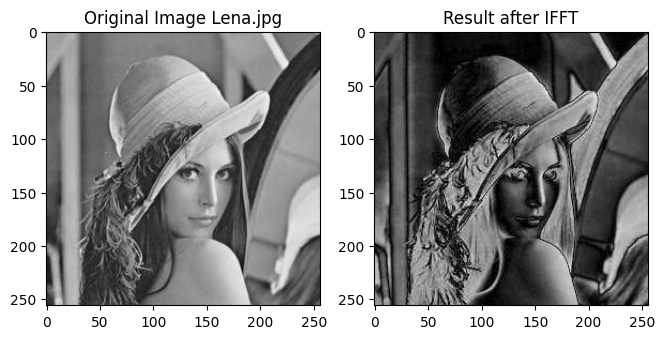

In [16]:
# read lena
lena = imageio.imread('Lena.jpg')
lena = lena.astype(np.float64)

#dft lena
dft_lena = np.fft.fft2(lena)
print(dft_lena[0][0])
print()

# H(0,0)=0
dft_lena[0][0] = 0
print(dft_lena[0][0])
print()
print(np.abs(dft_lena[0,0]))  # Πρέπει να είναι 0.0

# ifft
ifft_lena = np.fft.ifft2(dft_lena)
result = np.abs(ifft_lena)

#plot the imagies
plt.figure(figsize=(12,10))

plt.subplot(131)
plt.imshow(lena, cmap='gray')
plt.title('Original Image Lena.jpg')

plt.subplot(132)
plt.imshow(result, cmap='gray')
plt.title('Result after IFFT')

- **Η δεξιά εικόνα είναι πιο σκοτεινή επό την αρχική και είναι πιο έντονες οι λεπτομέρειες (ακμές, γραμμές) της εικόνας**
- **Το Η(0,0) είναι το συνολικό άθροισμα όλων των τιμών pixel**
- **Η μηδενική τιμή στη συχνότητα H(0,0) ισοδυναμεί με την αφαίρεση της μέσης τιμής της εικόνας.**
- **αφαιρείται η γενική φωτεινότητα, με αποτέλεσμα μια εικόνα με πιο έντονες ακμές και υψηλή αντίθεση, όπου κυριαρχούν οι τοπικές μεταβολές και όχι οι ομαλές περιοχές.**

# Άσκηση 3β

In [17]:
# read lena
lena = imageio.imread('Lena.jpg')
lena = lena.astype(np.float64)

#dft lena
dft_lena = np.fft.fft2(lena)
h0 = dft_lena[0][0] 

mean_value_lena = np.mean(lena)
print(f"Mean value of original image is: {mean_value_lena}")

print(f"Value of DFT image for H(0,0): {h0}")

height, width = lena.shape
mean_from_h00 = h0.real / (height * width)
print("Μέση τιμή από H(0,0):", mean_from_h00)

Mean value of original image is: 122.54096984863281
Value of DFT image for H(0,0): (8030845+0j)
Μέση τιμή από H(0,0): 122.54096984863281


- **Το Η(0,0) είναι το συνολικό άθροισμα όλων των τιμών pixel**
- **Διαιρώντας το άθροισμα όλων των pixels με το μέγεθος της εικόνας, παίρνω τη μέση τιμή της αρχικής εικόνας (όπως φαίνεται και στα νούμερα)**
- **Συμπέρασμα: Μέση τιμή = Re{H(0,0)} / (M*N)**
